# Loading Dataset and CNN
*Rolando A. Pula*

This notebook is a runnable version of the "Loading Dataset and CNN" slide deck, **extended with a hyperparameter-tuning study**. It walks through:

1. Loading a Dogs vs. Cats image dataset with OpenCV
2. Preprocessing the images (grayscale, resize, shuffle)
3. Saving/loading the prepared data with `pickle`
4. Building and training a Convolutional Neural Network (CNN) with TensorFlow/Keras to classify dogs vs. cats
5. **Manual hyperparameter tuning** (Trials 2-5, 50 epochs each, *no* early stopping) - from an intentionally over-fit baseline to a better-fit model
6. **Automated tuning with Keras Tuner** (`RandomSearch`) and a comparison against the manual trials

> **Before you run this notebook:** download the Kaggle "Dogs vs. Cats" dataset (e.g. `https://www.kaggle.com/c/dogs-vs-cats/data` or the mirrored `salader/dogs-vs-cats` dataset on Kaggle) and unzip it so you have two folders, `Dog/` and `Cat/`, each full of `.jpg` images. Then set `DATADIR` below to point at the parent folder that contains `Dog/` and `Cat/`.

## Requirements for Image Processing

- **GPU** (optional, speeds up training but not required)
- **OpenCV** (`cv2`) – for image processing
- **os module** – lets Python interface with the OS running on your computer (already in the standard library)
- **Data** – we'll use the Kaggle "Dogs vs. Cats" dataset

Run the cell below once to install the packages this notebook needs (skip it if they're already installed in your environment).

In [1]:
# Run this once if the packages below aren't already installed.
# %pip install opencv-python numpy matplotlib tensorflow

## Checking and installing OpenCV

The original slides show installing OpenCV through **Anaconda Navigator** (Environments tab → search `opencv` → Install). If you're not using Anaconda, the `pip install opencv-python` command in the cell above does the same thing.

## Calling the Necessary Modules

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2

## Data Preparation

Set `DATADIR` to the folder on your machine that contains the `Dog` and `Cat` subfolders (this replaces the original slide's hard-coded Windows path, `C:/Users/admin/Desktop/AMEN/Deep_Learning_class/Kaggle_dataset/PetImages`, with something you can edit for your own machine).

In [3]:
# Mount Google Drive when running in Colab; skip silently anywhere else.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running in Colab:", IN_COLAB)

Running in Colab: False


## Unzipping the Dataset

Given that the dataset is in a `.zip` file in Google Drive, we need to unzip it to a local directory before processing. I'll unzip `PetImages.zip` to `/content/` and then set `DATADIR` to this new location.

In [4]:
import zipfile
import os

# Colab only: unzip PetImages.zip from Google Drive (skipped if already unzipped / not in Colab)
zip_file_path = '/content/drive/MyDrive/PetImages.zip'
destination_dir = '/content/'

if IN_COLAB and not os.path.isdir('/content/PetImages'):
    os.makedirs(destination_dir, exist_ok=True)
    with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
        zip_ref.extractall(destination_dir)
    print(f"Unzipped '{zip_file_path}' to '{destination_dir}'")
else:
    print("Skipping unzip (already unzipped or not running in Colab).")

Skipping unzip (already unzipped or not running in Colab).


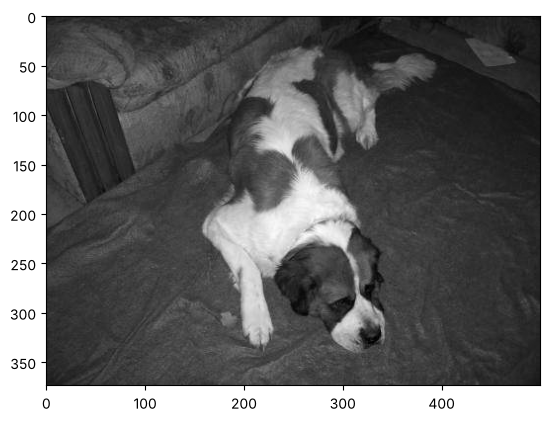

In [5]:
DATADIR = "/content/PetImages" if IN_COLAB else "PetImages"  # <- folder that contains your Dog/ and Cat/ folders
# this is the directory of your datasets
CATEGORIES = ["Dog", "Cat"]   # Defining the label as "Dog" or "Cat"

for category in CATEGORIES:
    path = os.path.join(DATADIR, category)  # path to cats or dogs dir
    for img in os.listdir(path):
        img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
        if img_array is None:
            # a handful of files in the Kaggle dataset are corrupted/unreadable - skip them
            continue

        # reading the image in the path and transforming it into an array
        # cv2.IMREAD_GRAYSCALE converts the image to grayscale so the CNN only has
        # to learn from one color channel instead of three (faster, smaller model)

        plt.imshow(img_array, cmap="gray")
        plt.show()
        break
    break

## Image Inspection

In [6]:
print(img_array)          # Displaying the image in array form (just for checking)
print(img_array.shape)    # checking the resolution of the image

[[28 29 32 ... 18 17 16]
 [33 34 35 ... 17 16 15]
 [36 36 35 ... 16 15 14]
 ...
 [31 31 31 ... 23 23 23]
 [31 32 32 ... 23 23 23]
 [29 30 31 ... 23 23 23]]
(374, 500)


## Image Resizing

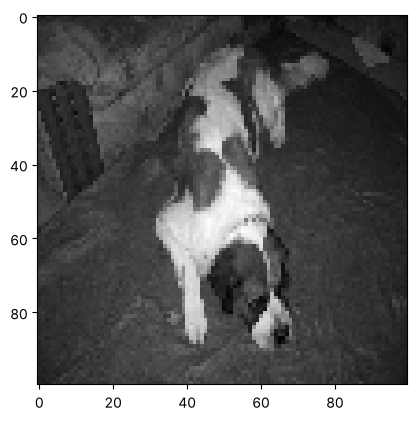

In [7]:
IMG_SIZE = 100  # initializing variable "IMG_SIZE" as 100

new_array = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
plt.imshow(new_array, cmap='gray')
plt.show()

## Assigning Training Data

In [8]:
training_data = []  # assigning training data

def create_training_data():
    for category in CATEGORIES:
        path = os.path.join(DATADIR, category)  # path to cats or dogs dir
        class_num = CATEGORIES.index(category)
        for img in sorted(os.listdir(path)):   # sorted -> reproducible order
            try:
                img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
                new_array = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
                training_data.append([new_array, class_num])
            except Exception as e:
                pass

create_training_data()

## Checking the Number of Training Data

In [9]:
print(len(training_data))

24989


## Randomizing/Shuffling the Data

In [10]:
import random
random.seed(42)            # fixed seed -> the same shuffle (and the same split) every run
random.shuffle(training_data)

for sample in training_data[:10]:
    print(sample[1])

0
1
0
1
0
1
0
1
0
1


## Assigning Variables for Features and Labels

In [11]:
X = []  # feature set
y = []  # labels

for features, label in training_data:
    X.append(features)
    y.append(label)

X = np.array(X).reshape(-1, IMG_SIZE, IMG_SIZE, 1)  # 1 is for grayscale
y = np.array(y)  # Keras expects the labels as an array too

## Using the Pickle Module

In [12]:
import pickle  # pickle lets you save your training data, avoiding recreating it
                # from scratch every time you want to adjust the model

with open('X.pickle', 'wb') as f:
    pickle.dump(X, f)

with open('y.pickle', 'wb') as g:
    pickle.dump(y, g)

## Using Pickle (Loading It Back)

In [13]:
pickle_in = open('X.pickle', 'rb')
X = pickle.load(pickle_in)

X[1]

array([[[241],
        [234],
        [236],
        ...,
        [215],
        [214],
        [215]],

       [[219],
        [220],
        [223],
        ...,
        [180],
        [178],
        [184]],

       [[186],
        [186],
        [188],
        ...,
        [167],
        [169],
        [172]],

       ...,

       [[254],
        [254],
        [255],
        ...,
        [193],
        [180],
        [176]],

       [[254],
        [254],
        [255],
        ...,
        [196],
        [192],
        [192]],

       [[252],
        [254],
        [255],
        ...,
        [205],
        [208],
        [209]]], shape=(100, 100, 1), dtype=uint8)

## What is a CNN?

**CNN** stands for **Convolutional Neural Network** — a type of neural network especially well suited to image data because it learns spatial patterns (edges, textures, shapes) through convolution and pooling layers instead of treating every pixel independently.

Further reading:
- https://medium.com/data-science-group-iitr/building-a-convolutional-neural-network-in-python-with-tensorflow-d251c3ca8117
- https://hackernoon.com/what-is-a-capsnet-or-capsule-network-2bfbe48769cc

## Using a CNN for Classification of Images

In [14]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Activation, Flatten, Conv2D, MaxPooling2D
import pickle

X = pickle.load(open('X.pickle', 'rb'))
y = pickle.load(open('y.pickle', 'rb'))

I0000 00:00:1791467758.495813    4749 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791467758.896836    4749 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791467761.567027    4749 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


# Hyperparameter Tuning: Manual vs. Keras Tuner

**Goal.** The model from the original notebook (the cell the professor pointed out) over-fits when it is trained for many epochs. The task is to
1. *manually* tune it toward a **best-fit** model (small train/validation gap, high validation accuracy, target ~90 %), then
2. let **Keras Tuner** search the hyperparameters automatically, and
3. compare the two approaches.

**Common protocol (identical for every run, so results are comparable)**

| Item | Value |
|---|---|
| Data | Dogs vs. Cats, grayscale, 100x100, pixels / 255 |
| Split | 10 % held-out **test**, then 20 % of the rest as **validation** (stratified, fixed seed) |
| Epochs | **50**, *no early stopping* (so over-fitting is visible in the curves) |
| Loss / metric | `binary_crossentropy` / accuracy |
| Batch size | 128 |
| Reported numbers | Final-epoch train / validation accuracy; test metrics of the final-epoch weights |

The *generalisation gap* = train accuracy - validation accuracy. A large gap (and a validation loss that climbs while training loss keeps falling) means over-fitting.

In [15]:
import json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
def set_seeds(seed=SEED):
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)
set_seeds()

EPOCHS = 50          # as instructed: 50 epochs, no early stopping
BATCH_SIZE = 128
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ---- load the pickled data and scale pixels to 0-1 ----
X = pickle.load(open('X.pickle', 'rb')).astype('float32') / 255.0
y = pickle.load(open('y.pickle', 'rb'))

# ---- 10 % held-out test set, then 20 % of the remainder as validation (stratified) ----
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.10, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.20, stratify=y_trainval, random_state=SEED)
print("train:", X_train.shape, " val:", X_val.shape, " test:", X_test.shape)

train: (17992, 100, 100, 1)  val: (4498, 100, 100, 1)  test: (2499, 100, 100, 1)


## Helper functions

`build_model(cfg)` builds a Conv2D network from a small configuration dictionary, so every manual trial and every Keras Tuner trial is built by exactly the same code. `run_trial(name, cfg)` trains the model for 50 epochs, evaluates it on validation and test data, draws the learning curves / confusion matrix, and caches the result in `results/` (re-running the notebook re-uses a finished trial instead of training again; delete `results/` to retrain everything).

In [16]:
def build_model(cfg):
    """cfg keys: filters (list), kernel, conv_act, dense (list), dense_act, dropout, lr, augment"""
    m = keras.Sequential(name=cfg.get("name", "cnn"))
    m.add(layers.Input(shape=X.shape[1:]))
    if cfg.get("augment", False):               # active during training only
        m.add(layers.RandomFlip("horizontal"))
        m.add(layers.RandomRotation(0.08))
        m.add(layers.RandomZoom(0.10))
    for f in cfg["filters"]:                    # Conv2D -> ReLU -> MaxPooling blocks
        m.add(layers.Conv2D(f, cfg.get("kernel", (3, 3)), activation=cfg.get("conv_act", "relu")))
        m.add(layers.MaxPooling2D(pool_size=(2, 2)))
    m.add(layers.Flatten())
    for u in cfg["dense"]:
        m.add(layers.Dense(u, activation=cfg.get("dense_act", "relu")))
        if cfg.get("dropout", 0) > 0:
            m.add(layers.Dropout(cfg["dropout"]))
    m.add(layers.Dense(1, activation="sigmoid"))
    m.compile(loss="binary_crossentropy",
              optimizer=keras.optimizers.Adam(learning_rate=cfg.get("lr", 1e-3)),
              metrics=["accuracy"])
    return m


class EveryN(keras.callbacks.Callback):
    """Print a short progress line every n epochs (keeps the notebook output readable)."""
    def __init__(self, name, n=5): super().__init__(); self.name, self.n = name, n
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.n == 0 or epoch == 0:
            line = (f"[{self.name}] epoch {epoch+1:>2}  loss {logs['loss']:.4f}  acc {logs['accuracy']:.4f}"
                    f"  val_loss {logs['val_loss']:.4f}  val_acc {logs['val_accuracy']:.4f}")
            print(line, flush=True)
            with open(f"{RESULTS_DIR}/progress.log", "a") as fh: fh.write(line + "\n")


class Checkpoint(keras.callbacks.Callback):
    """Save model + history after every epoch so an interrupted run can resume."""
    def __init__(self, name, ckpt, chist, prev, prev_time, t0):
        super().__init__(); self.ckpt, self.chist, self.prev, self.prev_time, self.t0 = ckpt, chist, prev, prev_time, t0
        self.hist = {k: list(v) for k, v in prev.items()}
    def on_epoch_end(self, epoch, logs=None):
        for k, v in logs.items(): self.hist.setdefault(k, []).append(float(v))
        tmp = self.ckpt.replace(".keras", "_tmp.keras"); self.model.save(tmp); os.replace(tmp, self.ckpt)
        json.dump({"history": self.hist, "elapsed": self.prev_time + time.time() - self.t0}, open(self.chist, "w"))


def run_trial(name, cfg, epochs=EPOCHS):
    jpath, mpath = f"{RESULTS_DIR}/{name}.json", f"{RESULTS_DIR}/{name}.keras"
    if os.path.exists(jpath) and os.path.exists(mpath):          # finished earlier -> reuse
        saved = json.load(open(jpath)); hist, train_time = saved["history"], saved["train_time_s"]
        model = keras.models.load_model(mpath)
        print(f"[{name}] loaded finished run from {RESULTS_DIR}/ (delete the folder to retrain)")
    else:
        keras.backend.clear_session(); set_seeds()
        ckpt, chist = f"{RESULTS_DIR}/{name}_ckpt.keras", f"{RESULTS_DIR}/{name}_ckpt.json"
        prev, init_epoch, prev_time = {}, 0, 0.0
        if os.path.exists(ckpt) and os.path.exists(chist):          # resume an interrupted run (e.g. Colab disconnect)
            model = keras.models.load_model(ckpt); sv = json.load(open(chist))
            prev, prev_time = sv["history"], sv["elapsed"]; init_epoch = len(prev["loss"])
            print(f"[{name}] resuming from epoch {init_epoch}")
        else:
            model = build_model(cfg)
        t0 = time.time()
        h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs, initial_epoch=init_epoch,
                      batch_size=cfg.get("batch_size", BATCH_SIZE), verbose=0,
                      callbacks=[EveryN(name), Checkpoint(name, ckpt, chist, prev, prev_time, t0)])
        train_time = prev_time + time.time() - t0
        hist = {k: list(prev.get(k, [])) + list(v) for k, v in h.history.items()}
        model.save(mpath)
        json.dump({"cfg": cfg, "history": hist, "train_time_s": train_time}, open(jpath, "w"))

    # ---- evaluation on the held-out test set ----
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    p = model.predict(X_test, verbose=0).ravel(); yhat = (p > 0.5).astype(int)
    rep = classification_report(y_test, yhat, target_names=CATEGORIES, output_dict=True, zero_division=0)
    cm = confusion_matrix(y_test, yhat)
    va = np.array(hist["val_accuracy"]); vl = np.array(hist["val_loss"])
    res = dict(name=name, params=int(model.count_params()), epochs=len(va),
               train_acc=hist["accuracy"][-1], val_acc=va[-1], gap=hist["accuracy"][-1] - va[-1],
               train_loss=hist["loss"][-1], val_loss=vl[-1],
               best_val_acc=float(va.max()), best_val_acc_epoch=int(va.argmax()) + 1,
               min_val_loss=float(vl.min()), min_val_loss_epoch=int(vl.argmin()) + 1,
               test_acc=test_acc, test_loss=test_loss,
               precision=rep["macro avg"]["precision"], recall=rep["macro avg"]["recall"], f1=rep["macro avg"]["f1-score"],
               train_time_min=train_time / 60, cfg=cfg, cm=cm.tolist())

    # ---- figures: learning curves + confusion matrix ----
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    ax[0].plot(hist["accuracy"], label="train"); ax[0].plot(hist["val_accuracy"], label="validation")
    ax[0].set_title(f"{name}: accuracy"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("accuracy"); ax[0].set_ylim(0.4, 1.0); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(hist["loss"], label="train"); ax[1].plot(hist["val_loss"], label="validation")
    ax[1].set_title(f"{name}: loss"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("binary cross-entropy"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/{name}_curves.png", dpi=130); plt.show()

    fig, ax = plt.subplots(figsize=(4.2, 3.8))
    im = ax.imshow(cm, cmap="Blues"); ax.set_title(f"{name}: confusion matrix (test)")
    ax.set_xticks([0, 1], CATEGORIES); ax.set_yticks([0, 1], CATEGORIES); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for i, j in np.ndindex(cm.shape):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/{name}_cm.png", dpi=130); plt.show()

    print(f"{name} | params {res['params']:,} | train acc {res['train_acc']:.4f} | val acc {res['val_acc']:.4f} | gap {res['gap']:+.4f}"
          f" | test acc {res['test_acc']:.4f} | test loss {res['test_loss']:.4f} | macro P/R/F1 {res['precision']:.3f}/{res['recall']:.3f}/{res['f1']:.3f}"
          f" | best val acc {res['best_val_acc']:.4f} @ epoch {res['best_val_acc_epoch']} | min val loss {res['min_val_loss']:.4f} @ epoch {res['min_val_loss_epoch']}"
          f" | {res['train_time_min']:.1f} min")
    json.dump({k: v for k, v in res.items()}, open(f"{RESULTS_DIR}/{name}_summary.json", "w"), indent=1)
    return res, model

ALL = {}   # collects every run for the final comparison table

# Part A - Manual hyperparameter tuning

Each trial changes a few things on purpose and records *why*. All other hyperparameters stay fixed (Adam, lr = 0.001, batch 128, 50 epochs, no early stopping).

## Trial 2 - Baseline: the original (over-fit) model

This is the architecture from the original notebook, but trained for the full 50 epochs instead of 5: Conv2D(**2**) -> Conv2D(64) -> Conv2D(64), two *linear* Dense(64) layers, no dropout. Its first layer is very narrow and it has no regularisation, so it is expected to memorise the training set.

[trial2_baseline] loaded finished run from results/ (delete the folder to retrain)


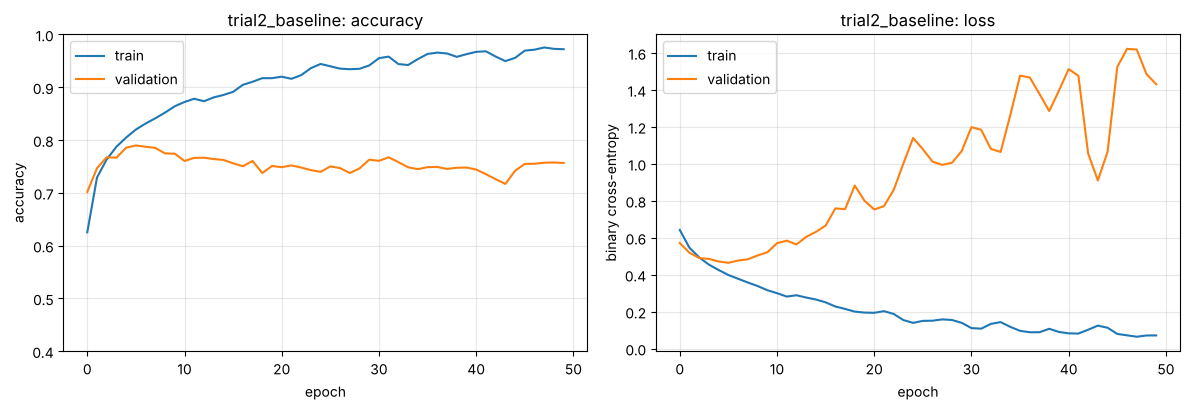

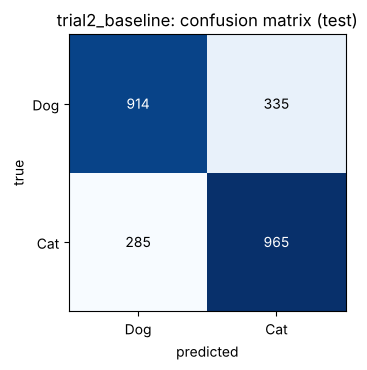

trial2_baseline | params 452,053 | train acc 0.9720 | val acc 0.7566 | gap +0.2155 | test acc 0.7519 | test loss 1.4635 | macro P/R/F1 0.752/0.752/0.752 | best val acc 0.7897 @ epoch 6 | min val loss 0.4640 @ epoch 6 | 31.9 min


In [17]:
cfg_t2 = dict(name="trial2_baseline", filters=[2, 64, 64], kernel=(3, 3), conv_act="relu",
              dense=[64, 64], dense_act=None, dropout=0.0, lr=1e-3, augment=False)
ALL["Trial 2 (baseline)"], m_t2 = run_trial("trial2_baseline", cfg_t2)

## Trial 3 - Widen the first layers (following the professor's hint)

Hint: start from `Conv2D(4, (3, 3))` and grow the first ReLU layer up to **16** filters, then keep adding capacity layer by layer. Here: 16 -> 32 -> 64 filters (ReLU, 3x3), a single ReLU Dense(64) layer, no dropout yet. This isolates the effect of *capacity / non-linearity*.

[trial3_wider] loaded finished run from results/ (delete the folder to retrain)


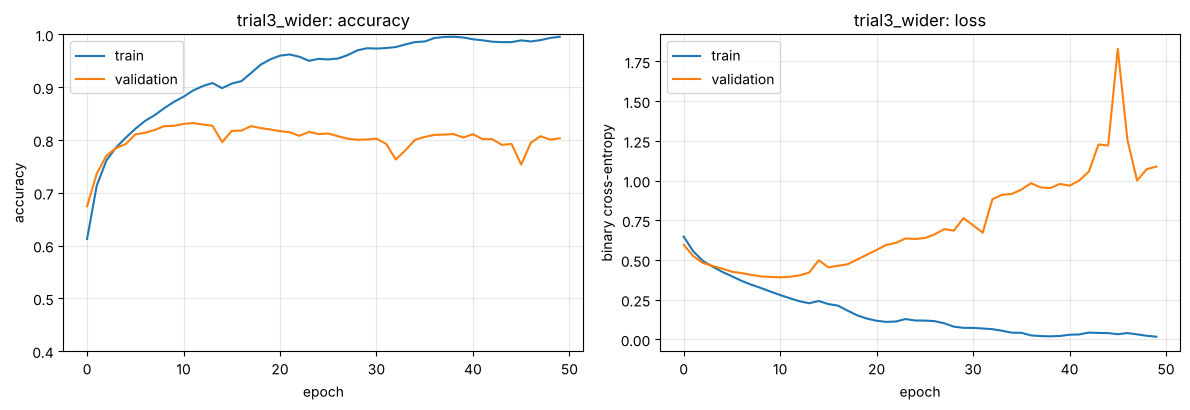

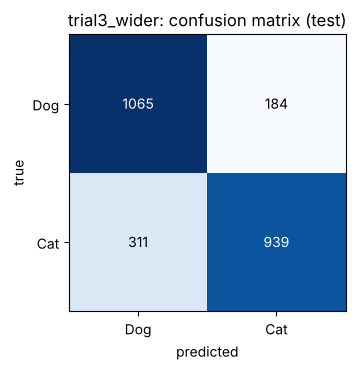

trial3_wider | params 433,025 | train acc 0.9957 | val acc 0.8032 | gap +0.1924 | test acc 0.8019 | test loss 1.1364 | macro P/R/F1 0.805/0.802/0.801 | best val acc 0.8321 @ epoch 12 | min val loss 0.3911 @ epoch 11 | 29.4 min


In [18]:
cfg_t3 = dict(name="trial3_wider", filters=[16, 32, 64], kernel=(3, 3), conv_act="relu",
              dense=[64], dense_act="relu", dropout=0.0, lr=1e-3, augment=False)
ALL["Trial 3 (16-32-64)"], m_t3 = run_trial("trial3_wider", cfg_t3)

## Trial 4 - Add regularisation (Dropout)

Same convolutional stack as Trial 3 but with a larger Dense layer (128) followed by **Dropout(0.5)**. Dropout randomly silences half of the dense units on every step, so the network cannot rely on co-adapted units; the goal is to shrink the train/validation gap.

[trial4_dropout] loaded finished run from results/ (delete the folder to retrain)


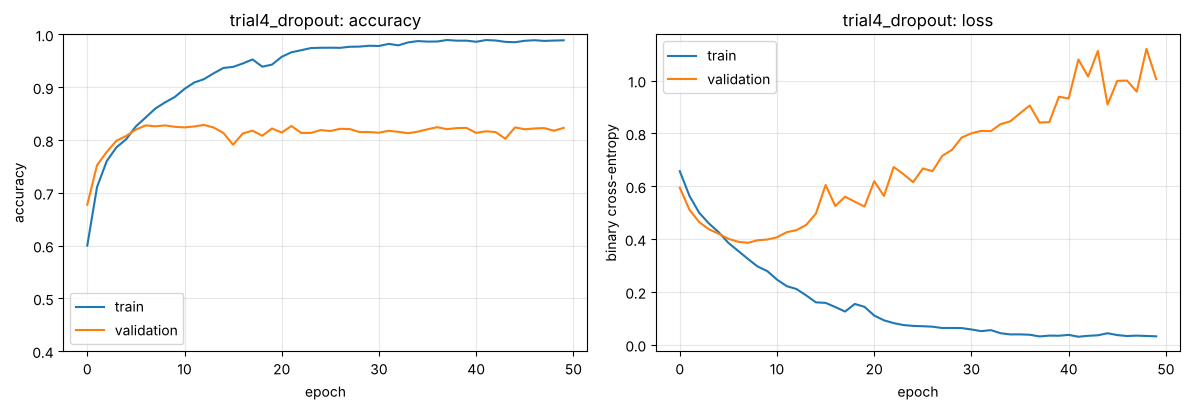

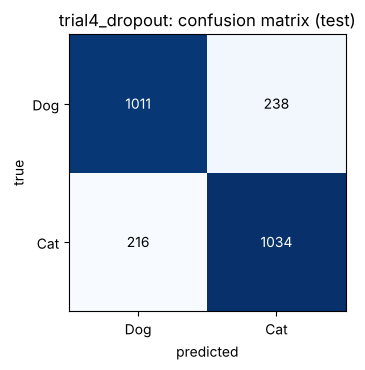

trial4_dropout | params 842,753 | train acc 0.9889 | val acc 0.8230 | gap +0.1659 | test acc 0.8183 | test loss 0.9973 | macro P/R/F1 0.818/0.818/0.818 | best val acc 0.8286 @ epoch 13 | min val loss 0.3859 @ epoch 8 | 28.8 min


In [19]:
cfg_t4 = dict(name="trial4_dropout", filters=[16, 32, 64], kernel=(3, 3), conv_act="relu",
              dense=[128], dense_act="relu", dropout=0.5, lr=1e-3, augment=False)
ALL["Trial 4 (+Dropout 0.5)"], m_t4 = run_trial("trial4_dropout", cfg_t4)

## Trial 5 - Another conv layer + data augmentation

"We can add another layer until we can tune": a 4th Conv2D block (16 -> 32 -> 64 -> 128) for more abstract features, Dropout(0.5), and light **data augmentation** (horizontal flip, +/-8 % rotation, 10 % zoom) applied only during training. Augmentation shows the network a slightly different version of each image every epoch, which attacks over-fitting at its source (too few distinct examples).

[trial5_deeper_aug] loaded finished run from results/ (delete the folder to retrain)


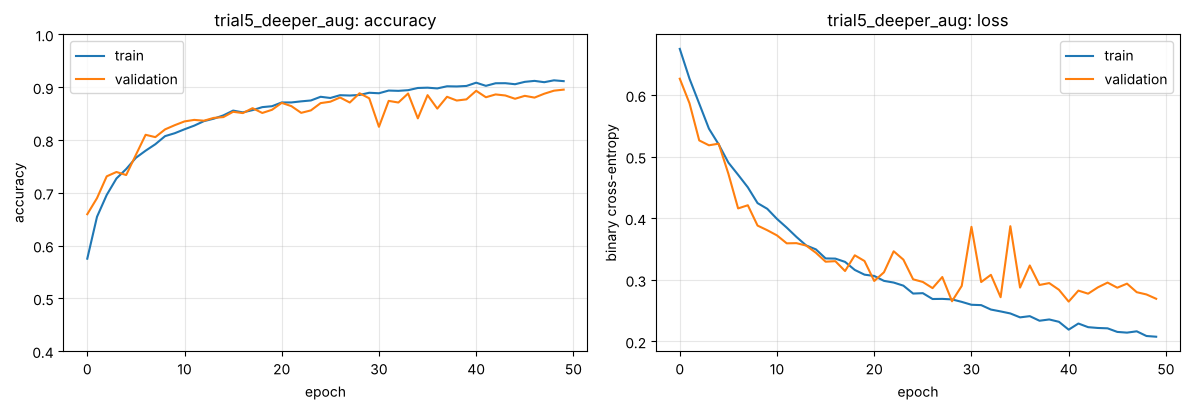

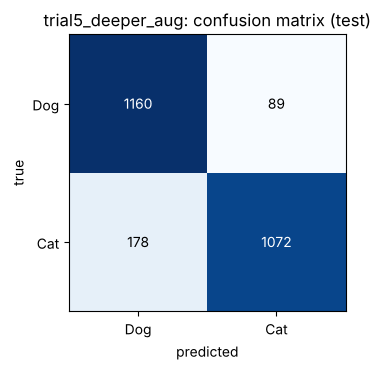

trial5_deeper_aug | params 359,553 | train acc 0.9116 | val acc 0.8955 | gap +0.0161 | test acc 0.8932 | test loss 0.2682 | macro P/R/F1 0.895/0.893/0.893 | best val acc 0.8955 @ epoch 50 | min val loss 0.2648 @ epoch 41 | 48.6 min


In [20]:
cfg_t5 = dict(name="trial5_deeper_aug", filters=[16, 32, 64, 128], kernel=(3, 3), conv_act="relu",
              dense=[128], dense_act="relu", dropout=0.5, lr=1e-3, augment=True)
ALL["Trial 5 (4 conv + aug)"], m_t5 = run_trial("trial5_deeper_aug", cfg_t5)

# Part B - Automated tuning with Keras Tuner

Instead of choosing values by hand, we declare a **search space** and let `keras_tuner.RandomSearch` try random combinations. Each candidate is trained for a short budget (10 epochs), ranked by `val_accuracy`, and the best configuration is then retrained for the same 50 epochs (no early stopping) and evaluated on the same test set as the manual trials.

Search space: number of conv blocks (2-4), base filters (4/8/16/32, doubling per block, capped at 128), dense units (32/64/128), dropout (0.0-0.5), learning rate (0.01/0.001/0.0001) and data augmentation (on/off). It is built with the same `build_model()` as the manual trials.

In [21]:
# %pip install -q keras-tuner      # uncomment if keras-tuner is not installed (Colab)
import keras_tuner as kt

def cfg_from_hp(hp):
    blocks = hp.Int("conv_blocks", 2, 4)
    base = hp.Choice("base_filters", [4, 8, 16, 32])
    return dict(name="tuner_candidate",
                filters=[min(base * 2 ** i, 128) for i in range(blocks)],
                kernel=(3, 3), conv_act="relu",
                dense=[hp.Choice("dense_units", [32, 64, 128])], dense_act="relu",
                dropout=hp.Float("dropout", 0.0, 0.5, step=0.1),
                lr=hp.Choice("learning_rate", [1e-2, 1e-3, 1e-4]),
                augment=hp.Boolean("augment"))

def hypermodel(hp):
    return build_model(cfg_from_hp(hp))

TUNER_EPOCHS, MAX_TRIALS = 10, 8
tuner = kt.RandomSearch(hypermodel, objective="val_accuracy", max_trials=MAX_TRIALS,
                        executions_per_trial=1, seed=SEED,
                        directory="kt_search", project_name="dogs_vs_cats")   # resumes if the folder already exists
tuner.search_space_summary()

Reloading Tuner from kt_search/dogs_vs_cats/tuner0.json
Search space summary
Default search space size: 6
conv_blocks (Int)
{'default': None, 'conditions': [], 'min_value': 2, 'max_value': 4, 'step': 1, 'sampling': 'linear'}
base_filters (Choice)
{'default': 4, 'conditions': [], 'values': [4, 8, 16, 32], 'ordered': True}
dense_units (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64, 128], 'ordered': True}
dropout (Float)
{'default': 0.0, 'conditions': [], 'min_value': 0.0, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}
augment (Boolean)
{'default': False, 'conditions': []}


In [22]:
tpath = f"{RESULTS_DIR}/tuner_time.json"
if os.path.exists(tpath):
    tuner_minutes = json.load(open(tpath))["minutes"]
    print("Search already finished earlier; reloaded from kt_search/ (took %.1f min)." % tuner_minutes)
t0 = time.time()
tuner.search(X_train, y_train, validation_data=(X_val, y_val), epochs=TUNER_EPOCHS, batch_size=BATCH_SIZE, verbose=2)
if not os.path.exists(tpath):
    tuner_minutes = (time.time() - t0) / 60
    json.dump({"minutes": tuner_minutes}, open(tpath, "w"))
print("Tuner search time: %.1f min" % tuner_minutes)

Search already finished earlier; reloaded from kt_search/ (took 24.0 min).
Tuner search time: 24.0 min


In [23]:
rows = []
for tr in tuner.oracle.trials.values():
    d = dict(tr.hyperparameters.values); d["val_accuracy (best epoch)"] = tr.score; d["trial"] = tr.trial_id
    rows.append(d)
tuner_df = pd.DataFrame(rows).sort_values("val_accuracy (best epoch)", ascending=False).reset_index(drop=True)
tuner_df.to_csv(f"{RESULTS_DIR}/tuner_trials.csv", index=False)
print(tuner_df.to_string())
best_hp = tuner.get_best_hyperparameters(1)[0]
print("\nBest hyperparameters:", best_hp.values)

   conv_blocks  base_filters  dense_units  dropout  learning_rate  augment  val_accuracy (best epoch) trial
0            4             4          128      0.0         0.0010    False                   0.784126     2
1            2             8          128      0.2         0.0010    False                   0.782348     3
2            2             8          128      0.2         0.0010     True                   0.746999     5
3            2             4           64      0.4         0.0010     True                   0.735438     7
4            2             4          128      0.3         0.0001    False                   0.726767     4
5            3             4           64      0.1         0.0001    False                   0.702090     0
6            3             4           64      0.1         0.0001     True                   0.649400     1
7            4             4           32      0.2         0.0100    False                   0.500222     6

Best hyperparameters: {'con

## Retrain the Keras Tuner's best configuration (50 epochs, no early stopping)

Same protocol as the manual trials, so the numbers are directly comparable.

{'name': 'tuner_best', 'filters': [4, 8, 16, 32], 'kernel': (3, 3), 'conv_act': 'relu', 'dense': [128], 'dense_act': 'relu', 'dropout': 0.0, 'lr': 0.001, 'augment': False}


[tuner_best] loaded finished run from results/ (delete the folder to retrain)


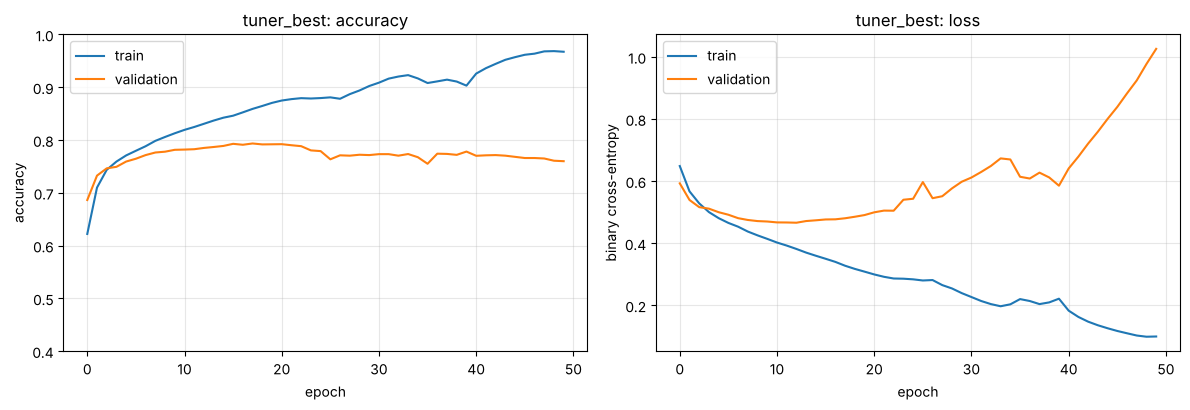

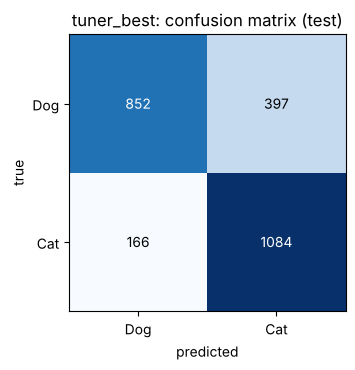

tuner_best | params 71,937 | train acc 0.9673 | val acc 0.7599 | gap +0.2074 | test acc 0.7747 | test loss 0.9695 | macro P/R/F1 0.784/0.775/0.773 | best val acc 0.7935 @ epoch 18 | min val loss 0.4661 @ epoch 13 | 12.9 min


In [24]:
cfg_best = cfg_from_hp(best_hp); cfg_best["name"] = "tuner_best"
print(cfg_best)
ALL["Keras Tuner (best)"], m_tuner = run_trial("tuner_best", cfg_best)

# Part C - Manual vs. Keras Tuner comparison

                   Run conv_filters dense  dropout    lr  augment  Params  Train acc  Val acc    Gap  Test acc  Test loss  Macro F1  Train time (min)
    Trial 2 (baseline)      2-64-64 64-64      0.0 0.001    False  452053     0.9720   0.7566 0.2155    0.7519     1.4635    0.7518              31.9
    Trial 3 (16-32-64)     16-32-64    64      0.0 0.001    False  433025     0.9957   0.8032 0.1924    0.8019     1.1364    0.8014              29.4
Trial 4 (+Dropout 0.5)     16-32-64   128      0.5 0.001    False  842753     0.9889   0.8230 0.1659    0.8183     0.9973    0.8183              28.8
Trial 5 (4 conv + aug) 16-32-64-128   128      0.5 0.001     True  359553     0.9116   0.8955 0.0161    0.8932     0.2682    0.8930              48.6
    Keras Tuner (best)    4-8-16-32   128      0.0 0.001    False   71937     0.9673   0.7599 0.2074    0.7747     0.9695    0.7728              12.9

Manual tuning: 4 trials x 50 epochs = 138.6 min of training (plus the time to think/decide between 

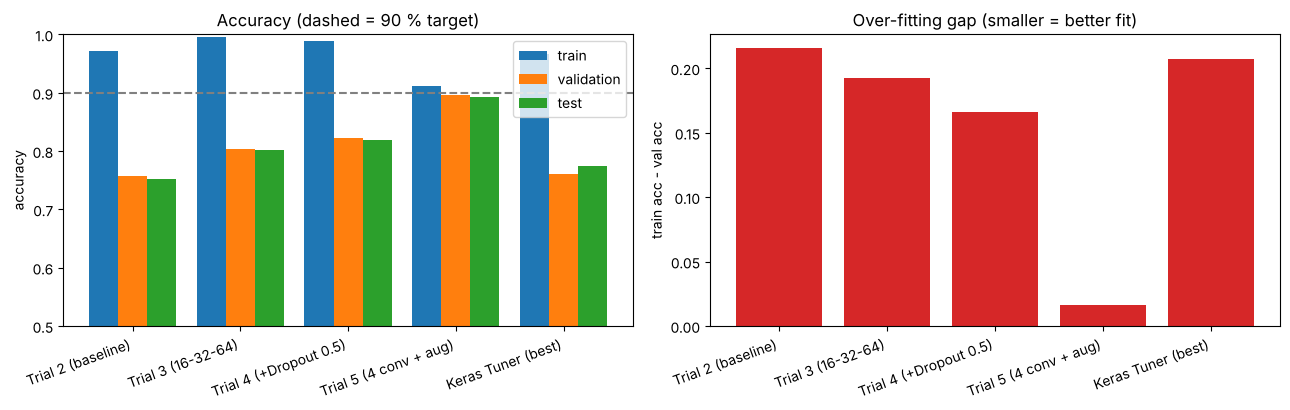

In [25]:
def fmt_cfg(c):
    return dict(conv_filters="-".join(map(str, c["filters"])), dense="-".join(map(str, c["dense"])),
                dropout=c.get("dropout", 0), lr=c.get("lr", 1e-3), augment=c.get("augment", False))

rows = []
for k, r in ALL.items():
    rows.append({"Run": k, **fmt_cfg(r["cfg"]), "Params": r["params"],
                 "Train acc": round(r["train_acc"], 4), "Val acc": round(r["val_acc"], 4), "Gap": round(r["gap"], 4),
                 "Test acc": round(r["test_acc"], 4), "Test loss": round(r["test_loss"], 4), "Macro F1": round(r["f1"], 4),
                 "Train time (min)": round(r["train_time_min"], 1)})
comp = pd.DataFrame(rows)
comp.to_csv(f"{RESULTS_DIR}/comparison.csv", index=False)
print(comp.to_string(index=False))

manual_minutes = sum(r["train_time_min"] for k, r in ALL.items() if k.startswith("Trial"))
print(f"\nManual tuning: {sum(k.startswith('Trial') for k in ALL)} trials x 50 epochs = {manual_minutes:.1f} min of training (plus the time to think/decide between trials).")
print(f"Keras Tuner : {MAX_TRIALS} candidates x {TUNER_EPOCHS} epochs = {tuner_minutes:.1f} min search + {ALL['Keras Tuner (best)']['train_time_min']:.1f} min final 50-epoch retrain, with no human intervention.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(comp)); w = 0.27
ax[0].bar(x - w, comp["Train acc"], w, label="train"); ax[0].bar(x, comp["Val acc"], w, label="validation"); ax[0].bar(x + w, comp["Test acc"], w, label="test")
ax[0].set_xticks(x, comp["Run"], rotation=20, ha="right"); ax[0].set_ylim(0.5, 1.0); ax[0].set_ylabel("accuracy"); ax[0].axhline(0.90, ls="--", c="gray"); ax[0].legend(); ax[0].set_title("Accuracy (dashed = 90 % target)")
ax[1].bar(x, comp["Gap"], color="tab:red"); ax[1].set_xticks(x, comp["Run"], rotation=20, ha="right"); ax[1].set_ylabel("train acc - val acc"); ax[1].set_title("Over-fitting gap (smaller = better fit)")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/comparison.png", dpi=130); plt.show()

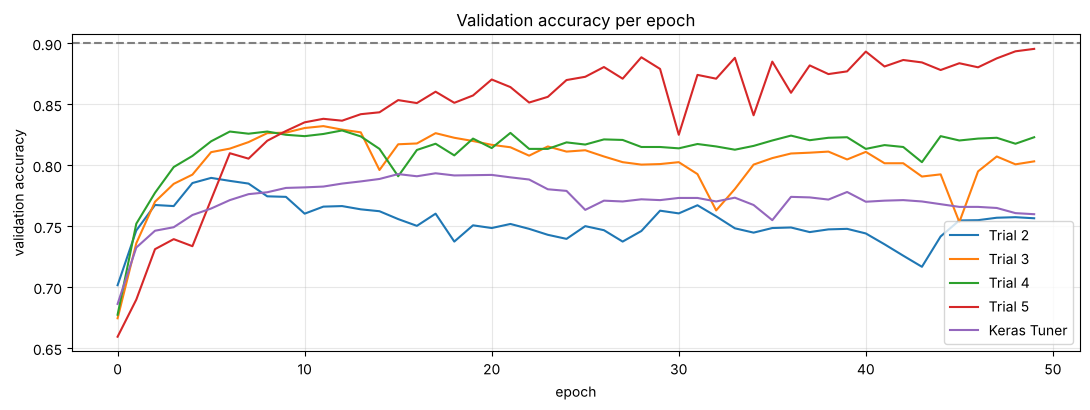

In [26]:
# Overlay of validation curves for all runs
plt.figure(figsize=(11, 4.2))
for nm, label in [("trial2_baseline", "Trial 2"), ("trial3_wider", "Trial 3"), ("trial4_dropout", "Trial 4"), ("trial5_deeper_aug", "Trial 5"), ("tuner_best", "Keras Tuner")]:
    h = json.load(open(f"{RESULTS_DIR}/{nm}.json"))["history"]
    plt.plot(h["val_accuracy"], label=label)
plt.axhline(0.90, ls="--", c="gray"); plt.xlabel("epoch"); plt.ylabel("validation accuracy"); plt.title("Validation accuracy per epoch"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/val_overlay.png", dpi=130); plt.show()

# Save the best model and run inference

The final model is chosen by **validation** accuracy (never by test accuracy), saved, reloaded and used for predictions on a few held-out test images.

Selected by validation accuracy: Trial 5 (4 conv + aug)


Model saved to and loaded from dog_cat_classifier.keras


Sample 1: predicted Cat (P(cat) = 97.2%), true = Cat
Sample 2: predicted Cat (P(cat) = 97.6%), true = Cat
Sample 3: predicted Cat (P(cat) = 94.6%), true = Cat
Sample 4: predicted Dog (P(cat) = 7.2%), true = Dog
Sample 5: predicted Dog (P(cat) = 23.4%), true = Dog


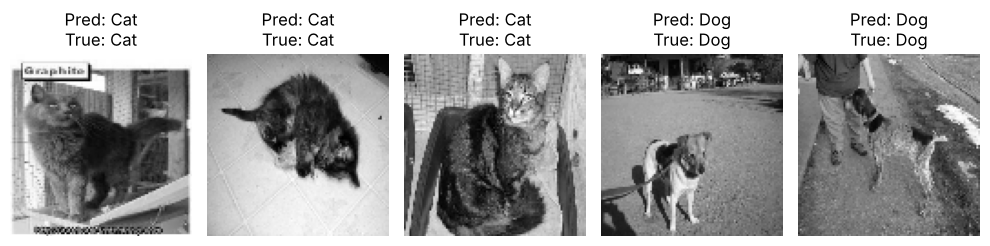

In [27]:
best_key = max(ALL, key=lambda k: ALL[k]["val_acc"])
print("Selected by validation accuracy:", best_key)
best_model = {"Trial 2 (baseline)": m_t2, "Trial 3 (16-32-64)": m_t3, "Trial 4 (+Dropout 0.5)": m_t4,
              "Trial 5 (4 conv + aug)": m_t5, "Keras Tuner (best)": m_tuner}[best_key]

model_filename = 'dog_cat_classifier.keras'
best_model.save(model_filename)
loaded_model = tf.keras.models.load_model(model_filename)
print(f"Model saved to and loaded from {model_filename}")

test_samples = X_test[:5]
inference_predictions = loaded_model.predict(test_samples, verbose=0)
plt.figure(figsize=(10, 4))
for i in range(5):
    prob_cat = float(inference_predictions[i][0])
    pred = 'Cat' if prob_cat > 0.5 else 'Dog'
    truth = CATEGORIES[y_test[i]]
    print(f"Sample {i+1}: predicted {pred} (P(cat) = {prob_cat*100:.1f}%), true = {truth}")
    plt.subplot(1, 5, i + 1)
    plt.imshow(test_samples[i].reshape(IMG_SIZE, IMG_SIZE), cmap='gray')
    plt.title(f"Pred: {pred}\nTrue: {truth}"); plt.axis('off')
plt.tight_layout(); plt.show()